In [1]:
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from tqdm import tqdm
from scipy.linalg import expm


# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


# Fig 4 (a)

In [3]:
Q = 4
PopSize = 10**12

def compete_four_pops_multinomial(tau, mu, nu, dt, PopSize=10**8, steps=None):


    # 16 types Pop[TR,VR]
    Pop = np.zeros((4,4), dtype=np.int64)

    
    Pop[0,1] = PopSize

    # environment favours VR =  1 → 2 → 3 → 1 → ...
    Hcycle = [
        np.array([0,1,0,0]),
        np.array([0,0,1,0]),
        np.array([0,0,0,1])
    ]
    Hindex = 0
    H = Hcycle[Hindex]

    next_switch = tau/dt

    freqTR=[]
    AvH=[]
    for k in range(steps):
        if k>0 and np.sum((freqTR[-1])[0,:])<0.45:
            break
        # ---- Environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % 3
            H = Hcycle[Hindex]
            next_switch += tau/dt

        # ---- SELECTION ----
        # growth factors for each VR
        w = np.exp(H * dt)  # size 4 vector

        # weighted population
        weighted = Pop * w  # broadcasting over VR
        total_fit = weighted.sum()

        # normalized reproduction probability per (TR,VR)
        P_repro = weighted / total_fit

        # sample next generation
        counts = P_repro.reshape(-1)
        new_counts = np.random.multinomial(PopSize, counts)
        Pop = new_counts.reshape(4,4)

        # ---- TR mutation (sequence mutation) ----
        # each TR mutates with rate mu to uniform TR
        for vr in range(4):
            for tr in range(4):
                count = Pop[tr,vr]
                if count == 0: continue

                # number mutating
                m = np.random.binomial(count, mu*dt)
                if m > 0:
                    Pop[tr,vr] -= m
                    # redistribute among TR=0..3
                    redist = np.random.multinomial(m, [1/4]*4)
                    Pop[:,vr] += redist

        # ---- VR switching (genotype change using DGR(TR)) ----
        for tr in range(4):
            for vr in range(4):
                count = Pop[tr,vr]
                if count == 0: continue

                # number switching genotype
                s = np.random.binomial(count, nu*dt)
                if s == 0:
                    continue

                Pop[tr,vr] -= s
                if tr!=0:
                    Pop[tr,tr]+=s
                else:
                    Pop[tr,:]+=np.random.multinomial(s, [1/4]*4)

        # statistics
        freqTR.append(Pop[:,:] / PopSize)
    return np.sum((freqTR[-1])[0,:]) #freq of A in system

def compute_f_not_A(mu, nu,tau):
    dt=0.1
    steps = max(int(tau/dt),10)
    freqA = compete_four_pops_multinomial(tau, mu, nu, dt=dt, PopSize=PopSize, steps=steps)
    return 1-freqA #freq of not A

In [4]:
# ======================
# paramètres globaux
# ======================
beta = 0.5
mu = 1e-4
nu_values = [1e-1, 1e-2,1e-3]


# ======================
# tirage Pareto de tau
# ======================
def sample_tau(tau0, beta):
    U = np.random.rand()
    return tau0 * U**(-1/beta)


# ======================
# une replica 
# ======================
def one_replica(tau0, nu):
    tau = sample_tau(tau0, beta)
    f_not_A = compute_f_not_A(mu, nu, tau)
    print(f_not_A)
    return 1.0 if f_not_A > 0.5 else 0.0 #lost A/ A not lost


# ======================
# estimation probabilité pour un tau0
# ======================
def estimate_prob_for_tau0(tau0, nu, Nrep):

    vals = Parallel(n_jobs=-1)(
        delayed(one_replica)(tau0, nu)
        for _ in range(Nrep)
    )

    return np.mean(vals)


# ======================
# calcul global
# ======================
def run_parallel(tau0_values, Nrep=20):

    results = {}

    for nu in nu_values:
        print(nu)
        probs = [
            estimate_prob_for_tau0(tau0, nu, Nrep)
            for tau0 in tau0_values
        ]

        results[nu] = np.array(probs)

    return results



tau0_values = np.logspace(0.5, 3, 7)

results = run_parallel(tau0_values, Nrep=400)

print("\nResults:")
for nu, vals in results.items():
    print(f"nu={nu} -> {vals}")



0.1
0.01
0.001

Results:
nu=0.1 -> [0.17   0.3075 0.425  0.7225 1.     1.     1.    ]
nu=0.01 -> [0.06  0.1   0.135 0.26  0.46  0.715 1.   ]
nu=0.001 -> [0.0275 0.06   0.0675 0.0975 0.175  0.3    0.4375]


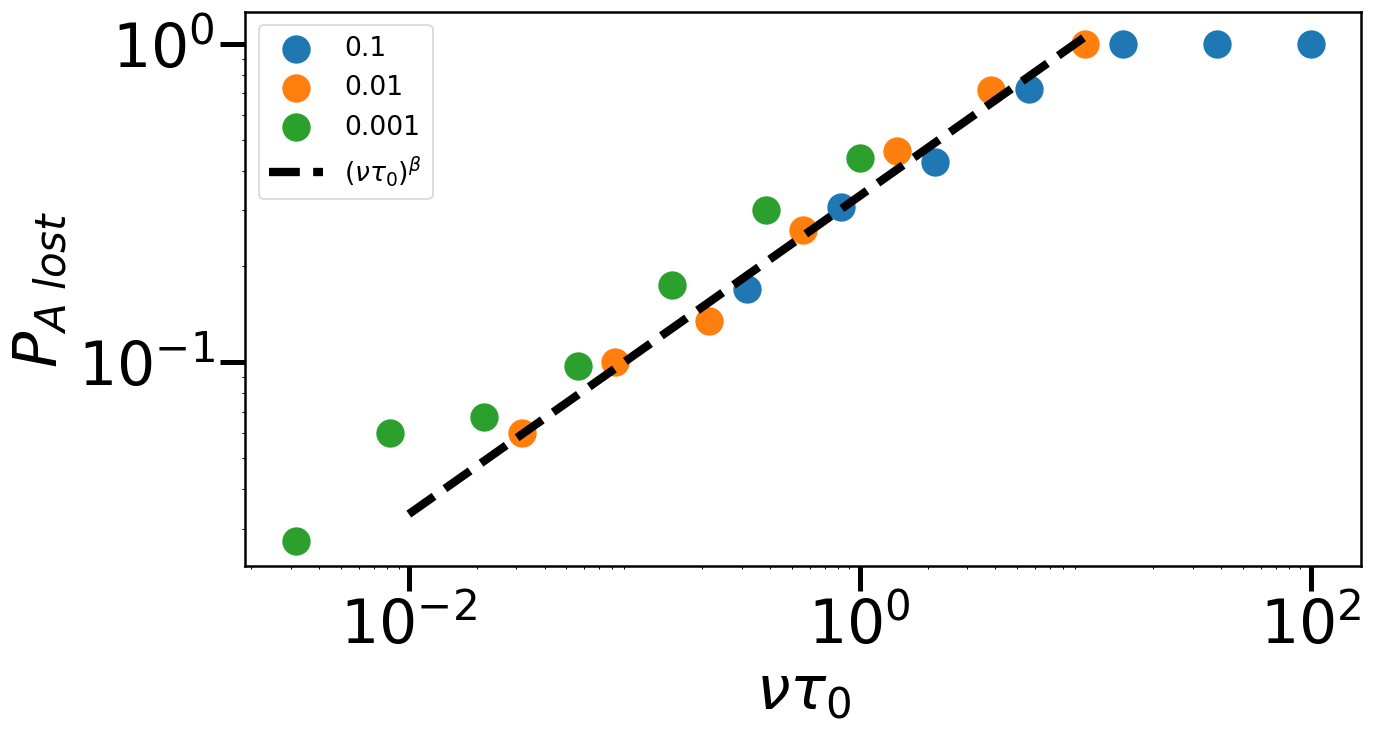

In [5]:
plt.figure(figsize=(12,6))
for nu in results:
    plt.scatter(nu*tau0_values,results[nu],label=nu)
x=np.logspace(-2,1,10)
plt.plot(x,x**beta/3,'--k',label=r'$\left(\nu \tau_0\right)^\beta$')
plt.xlabel(r'$\nu \tau_0$')
plt.ylabel(r'$P_{A~lost}$')
plt.legend()

plt.semilogx()
plt.semilogy()
plt.xticks([10**(-2),10**0,10**2],[r'$10^{-2}$',r'$10^0$',r'$10^{2}$'])

plt.savefig('P_lost_A.svg')

# Fig 4 (b)

In [3]:
# Parameters
mu = 1e-8
nu = 1e-3
Q = 4.0

def Amat(L,mu,nu,Q): # The matrix of rates
    A=np.zeros((L+2,L+2)) # L+1 is the garbage state
    for k in range(0,L+1):
        A[k,k]=-nu/Q**L+nu/Q**(L-k) #growth rate of TR with k nucleotides matching the best VR
        if k>=1:
            A[k,k-1]=mu/Q*(L-k+1) #transition rate k-1 -> k
        if k<L:
            A[k,k+1]=mu/Q*(k+1) #transition rate k+1 -> k
        A[L+1,k]=mu*L*(Q-2)/Q #TR with one bad nucleotide at least, neither an adenine or fittest nucleotide (the garbage)
    A[L+1,L+1]=mu*L*(Q-1)/Q-nu/Q**L #growth rate of the garbage
    return A

# Time evaluation
t_eval = np.linspace(0, 1000000, 10000)  # dense enough to get first-crossing accurately
dt=t_eval[-1]-t_eval[-2]
# Store results
first_times = []
theo_first_times=[]
Llist=np.unique(np.int64(np.logspace(0,np.log10(800),20)))

for L in Llist:
    print(L)
    # Initial condition
    f0_vec = np.zeros(L+2)
    f0_vec[0] = 1
    
    # Rate matrix
    A = Amat(L, mu, nu, Q)
    
    # Compute solution over time
    # Store solution
    f_t = np.zeros((L+2, len(t_eval)))
    f_t[:,0]=f0_vec[:]
    eA=expm(A * dt)
    for i in range(1,len(t_eval)):
        f_t[:, i] = eA @ f_t[:,i-1]  # exact solution at time t
        f_t[:, i]=f_t[:, i]/np.sum(f_t[:,i])
    f0_vals = f_t[0,:]
    sum_fk = f_t[1:,:].sum(axis=0)
    # Check first time condition is met
    condition = (f0_vals < 0.5) | (sum_fk > 0.5)
    if np.any(condition):
        first_time = t_eval[np.argmax(condition)]  # first True
    else:
        first_time = np.nan  # if never reaches condition
    
    first_times.append(first_time)
# Print results
for L, t in enumerate(first_times, start=1):
    print(f"L = {Llist[L-1]}: first time = {t:.4f}")

1
2
4
5
8
11
16
23
33
47
68
96
137
195
278
395
562


/tmp/ipykernel_7677/2481260369.py:9: RuntimeWarning: overflow encountered in power
  A[k,k]=-nu/Q**L+nu/Q**(L-k) #growth rate of TR with k nucleotides matching the best VR
/tmp/ipykernel_7677/2481260369.py:15: RuntimeWarning: overflow encountered in power
  A[L+1,L+1]=mu*L*(Q-1)/Q-nu/Q**L #growth rate of the garbage


800
L = 1: first time = 16901.6902
L = 2: first time = 26402.6403
L = 4: first time = 48304.8305
L = 5: first time = 59405.9406
L = 8: first time = 92309.2309
L = 11: first time = 124012.4012
L = 16: first time = 175417.5418
L = 23: first time = 244724.4724
L = 33: first time = 340234.0234
L = 47: first time = 468946.8947
L = 68: first time = 654365.4365
L = 96: first time = 913491.3491
L = 137: first time = 674867.4867
L = 195: first time = 474047.4047
L = 278: first time = 332533.2533
L = 395: first time = 234023.4023
L = 562: first time = 164516.4516
L = 800: first time = 115611.5612


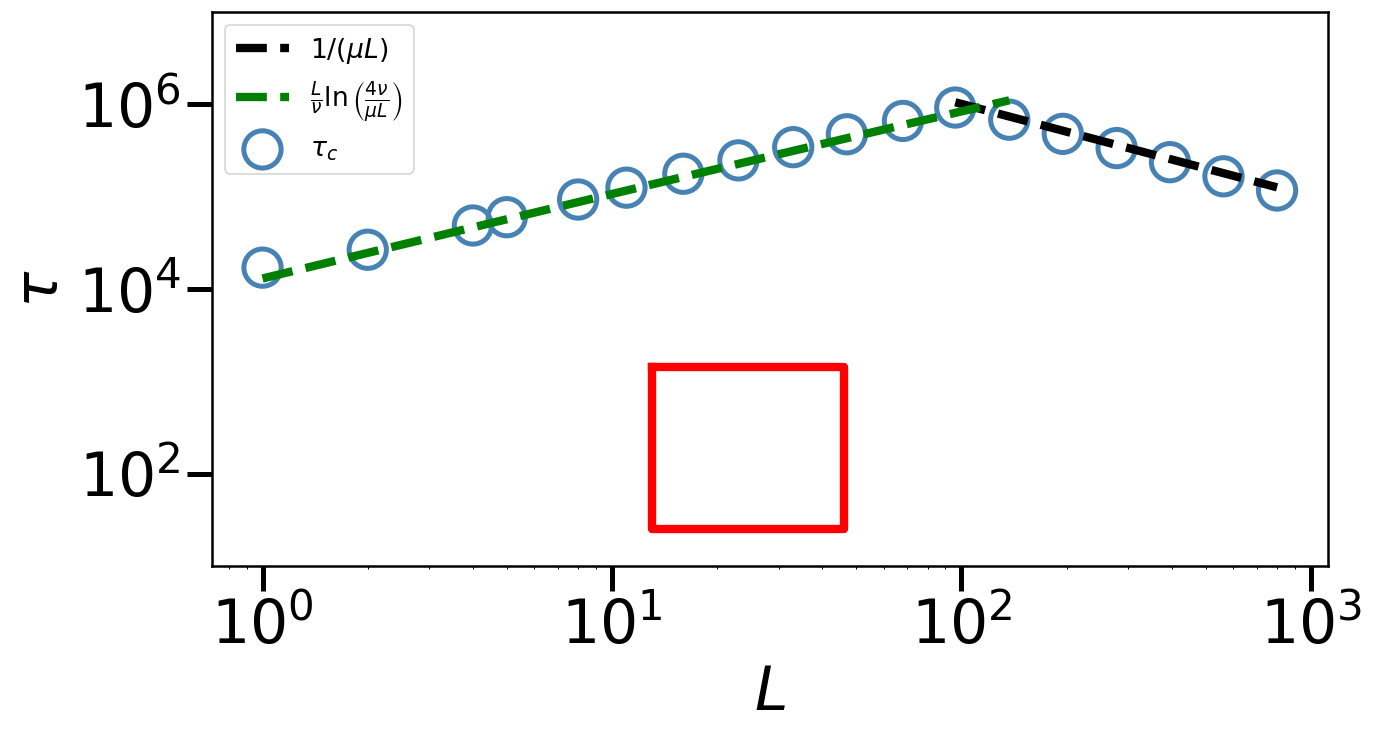

In [4]:
plt.figure(figsize=(12,6))

#plt.plot(Llist,theo_first_times,'o')

plt.plot(Llist[-7:],1/mu/Llist[-7:],'--k',label=r'$1/(\mu L)$')
plt.plot(Llist[:13],np.log(Q*nu/mu/Llist[:13])*Llist[:13]/nu,'--g',label=r'$\frac{L}{\nu}\ln \left(\frac{4 \nu}{\mu L} \right)$')

plt.scatter(Llist,np.array(first_times),s=500,linewidths=3, facecolors='none',edgecolors='steelblue',label=r'$\tau_c$')


plt.plot([13,13,46,46,13],1/np.array([7e-4,4e-2,4e-2,7e-4,7e-4]),'red')

plt.semilogy()
plt.semilogx()
plt.yticks([10**2,10**4,10**6])
plt.xticks()
plt.ylim((10**1,10**7))
plt.xlabel(r'$L$')
plt.ylabel(r'$\tau$')
plt.legend()

plt.savefig('Critical_loss_time_V0.svg')
#plt.savefig('Critical_loss_time.png')